In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import heapq


In [2]:
# Parameters for CTMC simulation
N = 1000
I0 = 5
R0 = 0
C0 = 0
S0 = N - I0 - R0
T = 100
dt = 1
time_points = np.arange(0, T + dt, dt)

# True parameters for simulation
beta_true = 0.00030   # Infection rate
alpha_true = 0.1    # Recovery rate

In [3]:
def simulate_ctmc_sir(beta, alpha, S0, I0, R0, T):
    t = 0
    S, I, R = S0, I0, R0
    times = [0]
    I_vals = [I]

    while t < T and I > 0:
        rate_infection = beta * S * I
        rate_recovery = alpha * I
        rate_total = rate_infection + rate_recovery

        if rate_total == 0:
            break

        t += np.random.exponential(1 / rate_total)
        if np.random.rand() < rate_infection / rate_total:
            S -= 1
            I += 1
        else:
            I -= 1
            R += 1

        if t <= T:
            times.append(t)
            I_vals.append(I)

    # Interpolate to uniform time grid
    I_interp = np.interp(time_points, times, I_vals)
    return I_interp

In [4]:
# Simulate CTMC data
I_ctmc = simulate_ctmc_sir(beta_true, alpha_true, S0, I0, R0, T)

In [5]:
def sir_ode(t, y, beta, alpha):
    S, I, R = y
    dSdt = -beta * S * I
    dIdt = beta * S * I - alpha * I
    dRdt = alpha * I
    return [dSdt, dIdt, dRdt]

In [6]:
# Define grid of parameters around true alpha and beta
beta_vals = np.linspace(beta_true * 0.5, beta_true * 1.5, 100)
alpha_vals = np.linspace(alpha_true * 0.5, alpha_true * 1.5, 100)

In [7]:
results = []

for beta in beta_vals:
    for alpha in alpha_vals:
        sol = solve_ivp(sir_ode, [0, T], [S0, I0, R0], t_eval=time_points, args=(beta, alpha))
        I_model = sol.y[1]
        ssr = np.sum((I_ctmc - I_model)**2)
        results.append((ssr, beta, alpha, I_model))

# Get 100 best-fit parameters
best_100 = heapq.nsmallest(100, results, key=lambda x: x[0])

In [8]:
def simulate_ctmc_cumulative(beta, alpha, S0, I0, R0, T):
    t = 0
    S, I, R = S0, I0, R0
    times = [0]
    C_vals = [0]  # Cumulative infections start at 0
    C = 0

    while t < T and I > 0:
        rate_infection = beta * S * I
        rate_recovery = alpha * I
        rate_total = rate_infection + rate_recovery

        if rate_total == 0:
            break

        tau = np.random.exponential(1 / rate_total)
        t += tau

        if np.random.rand() < rate_infection / rate_total:
            S -= 1
            I += 1
            C += 1  # Increment cumulative infections on new infection
        else:
            I -= 1
            R += 1

        if t <= T:
            times.append(t)
            C_vals.append(C)

    C_interp = np.interp(time_points, times, C_vals)
    return C_interp

In [9]:
C_ctmc = simulate_ctmc_cumulative(beta_true, alpha_true, S0, I0, R0, T)

In [10]:
def sir_ode_with_cumulative(t, y, beta, alpha):
    S, I, R, C = y
    dSdt = -beta * S * I
    dIdt = beta * S * I - alpha * I
    dRdt = alpha * I
    dCdt = beta * S * I
    return [dSdt, dIdt, dRdt, dCdt]

In [11]:
results_cumulative_uncontrolled = []

for beta in beta_vals:
    for alpha in alpha_vals:
        sol = solve_ivp(sir_ode_with_cumulative, [0, T], [S0, I0, R0, 0], t_eval=time_points, args=(beta, alpha))
        C_model = sol.y[3]
        ssr = np.sum((C_ctmc - C_model)**2)
        results_cumulative_uncontrolled.append((ssr, beta, alpha, C_model))

# Get top 100 fits based on cumulative SSR (uncontrolled)
best_100_cumulative = heapq.nsmallest(300, results_cumulative_uncontrolled, key=lambda x: x[0])


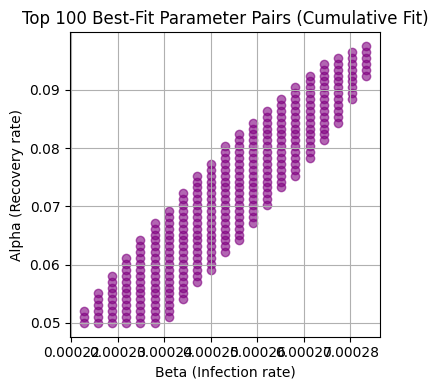

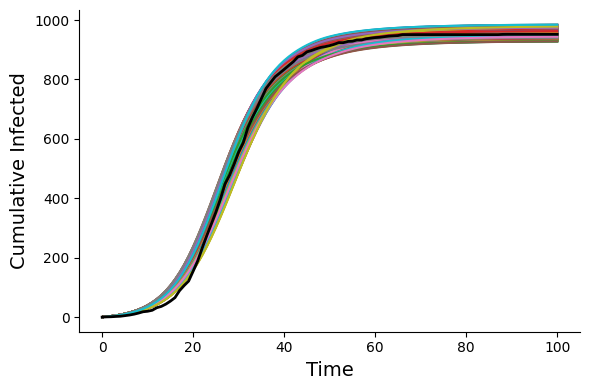

In [12]:
# Scatter plot of best 100 (beta, alpha)
betas_best_cum = [x[1] for x in best_100_cumulative]
alphas_best_cum = [x[2] for x in best_100_cumulative]

plt.figure(figsize=(4, 4))
plt.scatter(betas_best_cum, alphas_best_cum, c='purple', alpha=0.6)
plt.xlabel('Beta (Infection rate)')
plt.ylabel('Alpha (Recovery rate)')
plt.title('Top 100 Best-Fit Parameter Pairs (Cumulative Fit)')
plt.grid(True)
plt.tight_layout()
plt.show()


plt.figure(figsize=(6, 4))
for _, beta, alpha, C_model in best_100_cumulative:
    plt.plot(time_points, C_model, alpha=1)

plt.plot(time_points, C_ctmc, color='black', label='Data', linewidth=2)
plt.xlabel('Time', fontsize = 14)
plt.ylabel('Cumulative Infected', fontsize = 14)
#plt.title('Top 100 ODE Cumulative Infections vs CTMC')
#plt.legend()
#plt.grid(True)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['top'].set_visible(False)

plt.tight_layout()
plt.show()

In [13]:
def sir_ode_controlled_with_cumulative(t, y, beta, alpha):
    S, I, R, C = y
    if t >= 7:
        beta *= 0.4

    dSdt = -beta * S * I
    dIdt = beta * S * I - alpha * I
    dRdt = alpha * I
    dCdt = beta * S * I
    return [dSdt, dIdt, dRdt, dCdt]

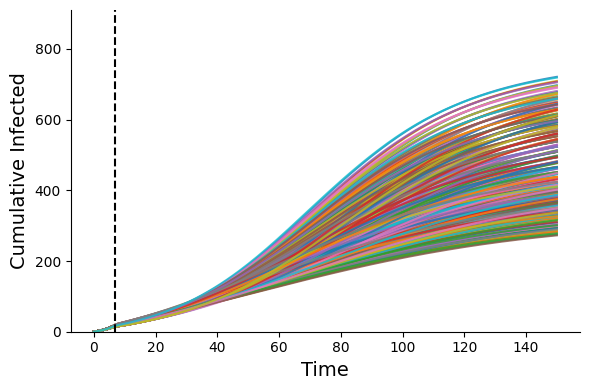

In [14]:
# Apply the control (reduce beta by 40% at t=7) on the top 100 parameter sets selected from cumulative SSR fit

controlled_cumulative_best100 = []

time_points = np.arange(0,151)
#time_points = np.arange(0, T + dt, dt)

for _, beta, alpha, _ in best_100_cumulative:
    sol = solve_ivp(sir_ode_controlled_with_cumulative, [0, T+200], [S0, I0, R0, 0], t_eval=time_points, args=(beta, alpha))
    C_controlled = sol.y[3]
    controlled_cumulative_best100.append(C_controlled)

# Plot controlled cumulative infections for best 100 cumulative-fit parameter sets
plt.figure(figsize=(6, 4))
for C_controlled in controlled_cumulative_best100:
    plt.plot(time_points, C_controlled, alpha=0.8)

#plt.plot(time_points, C_ctmc, color='red', label='CTMC Cumulative Infections', linewidth=2)
plt.axvline(7, color='black', linestyle='--', label='Control Applied (t=7)')
plt.xlabel('Time', fontsize = 14)
plt.ylabel('Cumulative Infected', fontsize = 14)
plt.ylim(0,910)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['top'].set_visible(False)
#plt.title('Controlled Cumulative Infections for Top 100 Cumulative-Fit Parameters')
#plt.legend()
#plt.grid(True)
plt.tight_layout()
plt.show()


In [15]:
time_points = np.arange(0,101)

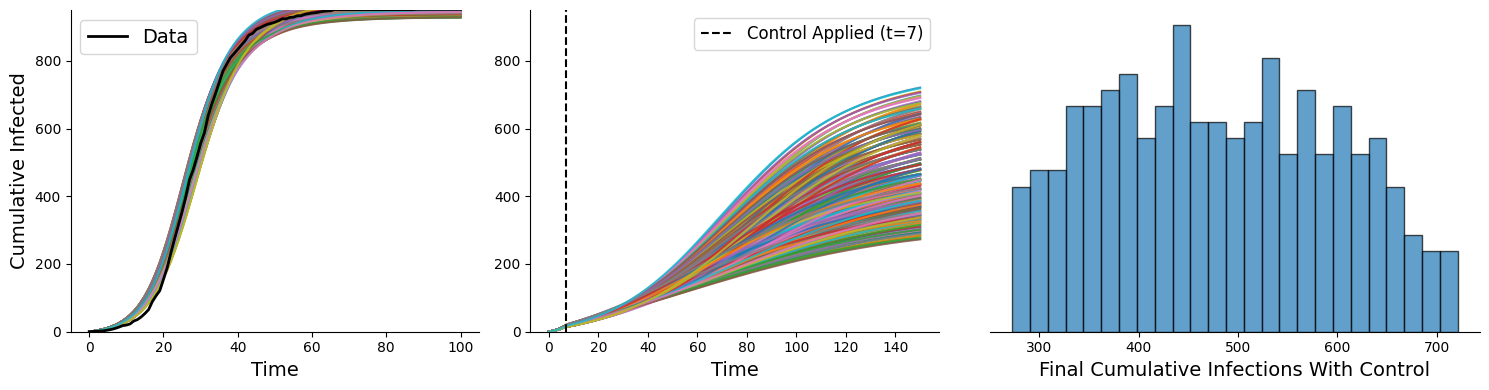

In [16]:
# Create the same figure, but adjust histogram height and hide y-axis ticks on histogram
fig, axs = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={'width_ratios': [1, 1, 1.2]}, sharey=False)


time_points = np.arange(0,101)

# Panel 1: Uncontrolled fits
for _, beta, alpha, C_model in best_100_cumulative:
    axs[0].plot(time_points, C_model, alpha=0.8)
axs[0].plot(time_points, C_ctmc, color='black', label='Data', linewidth=2)
axs[0].set_xlabel('Time', fontsize = 14)
axs[0].set_ylabel('Cumulative Infected', fontsize = 14)
axs[0].legend(fontsize = 14)
axs[0].set_ylim(0,950)
axs[0].spines['right'].set_visible(False)
axs[0].spines['top'].set_visible(False)

# Panel 2: Controlled fits
time_points = np.arange(0,151)
for C_controlled in controlled_cumulative_best100:
    axs[1].plot(time_points, C_controlled, alpha=0.8)
axs[1].axvline(7, color='black', linestyle='--', label='Control Applied (t=7)')
axs[1].set_xlabel('Time', fontsize = 14)
axs[1].set_ylim(0,950)
axs[1].legend(fontsize = 12)
axs[1].spines['right'].set_visible(False)
axs[1].spines['top'].set_visible(False)

# Panel 3: Histogram
final_cumulative_values = [C[-1] for C in controlled_cumulative_best100]
axs[2].hist(final_cumulative_values, bins=25, edgecolor='black', alpha = 0.7)
#axs[2].axvline(C_ctmc[-1], color='black', linestyle='--', label='Control Applied (t=7)')
axs[2].set_xlabel('Final Cumulative Infections With Control', fontsize = 14)
axs[2].spines['right'].set_visible(False)
axs[2].spines['top'].set_visible(False)
axs[2].spines['left'].set_visible(False)
axs[2].tick_params(axis='y', left=False, labelleft=False)

plt.tight_layout()
plt.show()
